In [1]:
import pandas
import numpy as np
import matplotlib.pyplot as plot
from sklearn import linear_model
from sklearn.model_selection import train_test_split

            exam1       exam2    decision
count  100.000000  100.000000  100.000000
mean    65.644274   66.221998    0.600000
std     19.458222   18.582783    0.492366
min     30.058822   30.603263    0.000000
25%     50.919511   48.179205    0.000000
50%     67.032988   67.682381    1.000000
75%     80.212529   79.360605    1.000000
max     99.827858   98.869436    1.000000


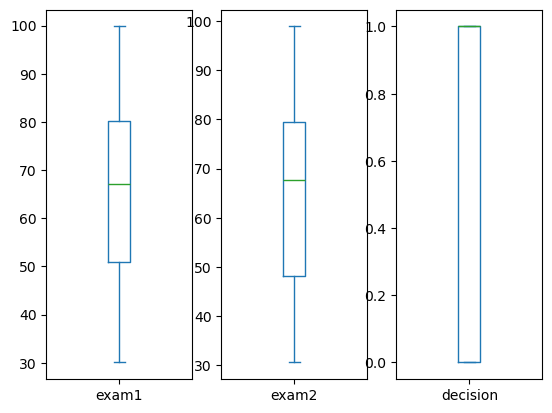

In [2]:
data = pandas.read_csv('acceptance_data.txt', names = ['exam1','exam2','decision'])

# Step 1
print(data.describe())
data.plot(kind='box', subplots=True)
plot.show()

   exam1  exam2
0  34.62  78.02
1  30.29  43.89
2  35.85  72.90
3  60.18  86.31
4  79.03  75.34
<class 'pandas.DataFrame'>


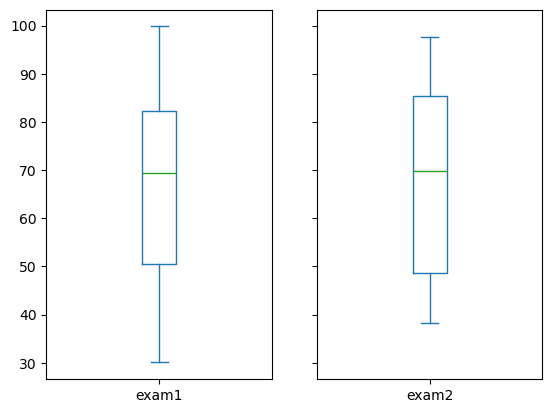

In [3]:
# Steps 2 and 3
X = data.drop(columns=['decision']).round(2)
y = data['decision']

print(X.head())

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=100)

print(type(X_train))
X_train.plot(kind='box', subplots=True, sharey=True)
plot.show()


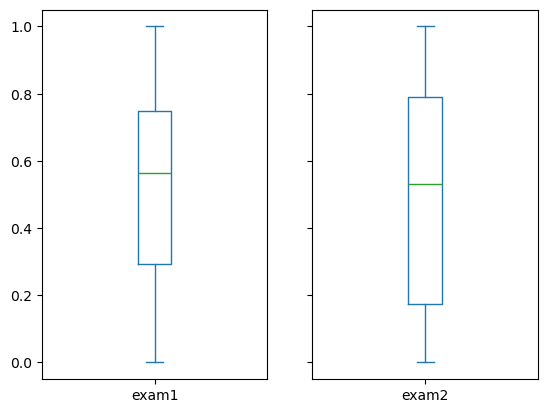

In [4]:
# Task 1: Perform feature scaling
xmin = X_train.min()
xmax = X_train.max()
X_train = (X_train - xmin) / (xmax - xmin)
X_test = (X_test - xmin) / (xmax-xmin)
X_train.plot(kind='box', subplots=True, sharey=True)
plot.show()

In [5]:
X_train = X_train.to_numpy().reshape((-1,2))
X_test = X_test.to_numpy().reshape((-1,2))
y_train = y_train.to_numpy() # What if the decision was "Yes" and "No"?
y_test = y_test.to_numpy()

In [6]:
# Step 4
model = linear_model.LogisticRegression(solver='sag')
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'sag'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties

In [7]:
print('Coefficients: \n', model.coef_, " ", model.intercept_)

# Step 5
y_pred = model.predict(X_test)
print('Correct predicitions ratio: %.2f'% model.score(X_test, y_test))

Coefficients: 
 [[2.90222005 2.32171907]]   [-2.10494247]
Correct predicitions ratio: 0.88


In [8]:
y_pred

array([1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0,
       1, 1, 0])

In [9]:
# Step 6
new_x = [75,82]
model.predict([(new_x-xmin)/(xmax-xmin)])

array([1])

In [ ]:
# Task 2:
def predict_class(x_data):
    x_data = (x_data - xmin) / (xmax - xmin)
    return model.predict([x_data])


# Task 3:
def calc_accuracy(y_true, y_pred):
    return np.sum(y_true == y_pred) / len(y_true)


# Task 4: Test these 2 functions
y_pred = np.array([
    np.asarray(predict_class(x)).reshape(-1)[0]
    for x in X_test
])

accuracy = calc_accuracy(np.asarray(y_test), y_pred)

print("Predictions:", y_pred)
print(f"Accuracy: {accuracy:.2%}")